# 06 — CNN + BiGRU PPG + IMU Fusion Model

This notebook evaluates a CNN + BiGRU sensor-fusion architecture for heart-rate regression.

Architecture:

`PPG -> Conv1D -> Conv1D -> BiGRU -> feature vector`

`IMU -> Conv1D -> Conv1D -> BiGRU -> feature vector`

Then both branches are concatenated and used to predict chest-strap HR.

The same exact 8-second windows, 320 points, train/validation/test split, timing QC and target definition are reused. Nothing is saved to disk.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Re-run preprocessing

In [2]:
%%capture preprocessing_output
%run ./02_preprocessing_windowing.ipynb

## 3. Prepare PPG and IMU branches

In [3]:
X_ppg_train_rnn = X_fusion_train[:, :, 0:1]
X_ppg_val_rnn   = X_fusion_val[:, :, 0:1]
X_ppg_test_rnn  = X_fusion_test[:, :, 0:1]

X_imu_train_rnn = X_fusion_train[:, :, 1:4]
X_imu_val_rnn   = X_fusion_val[:, :, 1:4]
X_imu_test_rnn  = X_fusion_test[:, :, 1:4]

print("PPG:", X_ppg_train_rnn.shape, X_ppg_val_rnn.shape, X_ppg_test_rnn.shape)
print("IMU:", X_imu_train_rnn.shape, X_imu_val_rnn.shape, X_imu_test_rnn.shape)

assert X_ppg_train_rnn.shape[1:] == (320, 1)
assert X_imu_train_rnn.shape[1:] == (320, 3)

PPG: (1322, 320, 1) (281, 320, 1) (292, 320, 1)
IMU: (1322, 320, 3) (281, 320, 3) (292, 320, 3)


## 4. Training-only normalization

In [4]:
ppg_mean = X_ppg_train_rnn.mean(axis=(0, 1), keepdims=True)
ppg_std  = X_ppg_train_rnn.std(axis=(0, 1), keepdims=True)

imu_mean = X_imu_train_rnn.mean(axis=(0, 1), keepdims=True)
imu_std  = X_imu_train_rnn.std(axis=(0, 1), keepdims=True)

if np.any(ppg_std == 0) or np.any(imu_std == 0):
    raise ValueError("Zero standard deviation detected.")

X_ppg_train_norm = (X_ppg_train_rnn - ppg_mean) / ppg_std
X_ppg_val_norm   = (X_ppg_val_rnn - ppg_mean) / ppg_std
X_ppg_test_norm  = (X_ppg_test_rnn - ppg_mean) / ppg_std

X_imu_train_norm = (X_imu_train_rnn - imu_mean) / imu_std
X_imu_val_norm   = (X_imu_val_rnn - imu_mean) / imu_std
X_imu_test_norm  = (X_imu_test_rnn - imu_mean) / imu_std

display(pd.DataFrame({
    "Channel": ["PPG_Raw", "ACC_X", "ACC_Y", "ACC_Z"],
    "Train_Mean": [float(ppg_mean.reshape(-1)[0]), *imu_mean.reshape(-1).tolist()],
    "Train_Std": [float(ppg_std.reshape(-1)[0]), *imu_std.reshape(-1).tolist()],
}).round(5))

,Channel,Train_Mean,Train_Std
0,PPG_Raw,4475.98584,1247.35583
1,ACC_X,-0.32539,0.55772
2,ACC_Y,0.34338,0.23384
3,ACC_Z,-0.67551,0.31986


## 5. Reproducibility

In [5]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 6. Build CNN + BiGRU model

In [6]:
def build_cnn_bigru_model():
    ppg_input = tf.keras.layers.Input(shape=(320, 1), name="ppg_input")
    p = tf.keras.layers.Conv1D(32, 7, padding="same", activation="relu")(ppg_input)
    p = tf.keras.layers.BatchNormalization()(p)
    p = tf.keras.layers.MaxPooling1D(2)(p)
    p = tf.keras.layers.Conv1D(64, 5, padding="same", activation="relu")(p)
    p = tf.keras.layers.BatchNormalization()(p)
    p = tf.keras.layers.MaxPooling1D(2)(p)
    p = tf.keras.layers.Bidirectional(
        tf.keras.layers.GRU(48, dropout=0.10),
        name="ppg_bigru"
    )(p)
    p = tf.keras.layers.Dense(64, activation="relu")(p)

    imu_input = tf.keras.layers.Input(shape=(320, 3), name="imu_input")
    m = tf.keras.layers.Conv1D(32, 7, padding="same", activation="relu")(imu_input)
    m = tf.keras.layers.BatchNormalization()(m)
    m = tf.keras.layers.MaxPooling1D(2)(m)
    m = tf.keras.layers.Conv1D(64, 5, padding="same", activation="relu")(m)
    m = tf.keras.layers.BatchNormalization()(m)
    m = tf.keras.layers.MaxPooling1D(2)(m)
    m = tf.keras.layers.Bidirectional(
        tf.keras.layers.GRU(48, dropout=0.10),
        name="imu_bigru"
    )(m)
    m = tf.keras.layers.Dense(64, activation="relu")(m)

    fused = tf.keras.layers.Concatenate(name="feature_fusion")([p, m])
    fused = tf.keras.layers.Dropout(0.30)(fused)
    fused = tf.keras.layers.Dense(64, activation="relu")(fused)
    fused = tf.keras.layers.Dropout(0.20)(fused)
    output = tf.keras.layers.Dense(1, name="predicted_hr")(fused)

    model = tf.keras.Model(
        inputs=[ppg_input, imu_input],
        outputs=output,
        name="CNN_BiGRU_PPG_IMU_Fusion"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )
    return model

cnn_bigru_model = build_cnn_bigru_model()
cnn_bigru_model.summary()

Model: "CNN_BiGRU_PPG_IMU_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ppg_input           │ (None, 320, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imu_input           │ (None, 320, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 320, 32)   │        256 │ ppg_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 320, 32)   │        704 │ imu_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 320, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 320, 32)   │        128 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 160, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 160, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 160, 64)   │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 160, 64)   │     10,304 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 64)   │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 80, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 80, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ppg_bigru           │ (None, 96)        │     32,832 │ max_pooling1d_1[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imu_bigru           │ (None, 96)        │     32,832 │ max_pooling1d_3[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      6,208 │ ppg_bigru[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      6,208 │ imu_bigru[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 128)       │          0 │ dense[0][0],    

 Total params: 108,737 (424.75 KB)

 Trainable params: 108,353 (423.25 KB)

 Non-trainable params: 384 (1.50 KB)

## 7. Callbacks

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=18,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1
    )
]

## 8. Train

In [ ]:
history = cnn_bigru_model.fit(
    [X_ppg_train_norm, X_imu_train_norm],
    y_train,
    validation_data=([X_ppg_val_norm, X_imu_val_norm], y_val),
    epochs=180,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

## 9. Training history

Epochs trained: 39
Best epoch    : 21


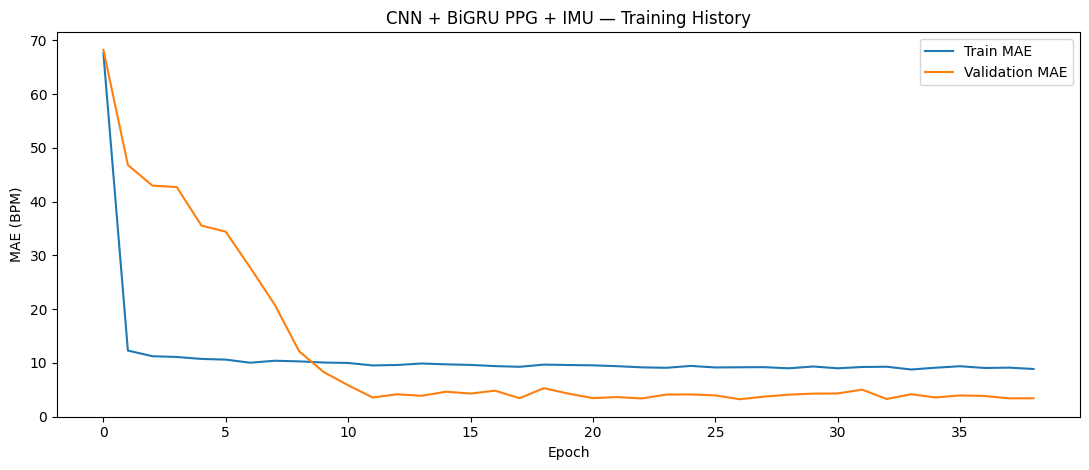

In [9]:
history_df = pd.DataFrame(history.history)
best_epoch = int(history_df["val_loss"].idxmin() + 1)

print("Epochs trained:", len(history_df))
print("Best epoch    :", best_epoch)

plt.figure(figsize=(11, 4.8))
plt.plot(history_df["mae"], label="Train MAE")
plt.plot(history_df["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (BPM)")
plt.title("CNN + BiGRU PPG + IMU — Training History")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Test predictions

In [10]:
y_pred_cnn_bigru = cnn_bigru_model.predict(
    [X_ppg_test_norm, X_imu_test_norm],
    verbose=0
).reshape(-1)

print("Predictions:", y_pred_cnn_bigru.shape)

Predictions: (292,)


## 11. Metric function

In [11]:
def regression_metrics(y_true, y_prediction):
    y_true = np.asarray(y_true, dtype=float)
    y_prediction = np.asarray(y_prediction, dtype=float)

    mae = mean_absolute_error(y_true, y_prediction)
    rmse = np.sqrt(mean_squared_error(y_true, y_prediction))
    r2 = r2_score(y_true, y_prediction)

    if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_prediction) > 0:
        correlation = np.corrcoef(y_true, y_prediction)[0, 1]
    else:
        correlation = np.nan

    return {
        "MAE_BPM": mae,
        "RMSE_BPM": rmse,
        "R2": r2,
        "Correlation": correlation,
        "True_Mean": np.mean(y_true),
        "True_Std": np.std(y_true),
        "Pred_Mean": np.mean(y_prediction),
        "Pred_Std": np.std(y_prediction),
    }

## 12. Overall CNN + BiGRU metrics

In [12]:
cnn_bigru_overall_metrics = regression_metrics(
    y_test,
    y_pred_cnn_bigru
)

display(pd.DataFrame([{
    "Model": "CNN + BiGRU PPG + IMU",
    **cnn_bigru_overall_metrics
}]).round(3))

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,CNN + BiGRU PPG + IMU,3.865,6.243,0.93,0.966,89.163,23.663,88.369,23.745


## 13. Global mean + activity-mean diagnostics

In [13]:
global_mean_hr = float(np.mean(y_train))
global_mean_pred = np.full(len(y_test), global_mean_hr, dtype=float)
global_mean_metrics = regression_metrics(y_test, global_mean_pred)

train_activity = meta_train["Activity"].to_numpy()
test_activity = meta_test["Activity"].to_numpy()

activity_mean_map = {}
for activity in ACTIVITY_ORDER:
    mask = train_activity == activity
    if np.any(mask):
        activity_mean_map[activity] = float(np.mean(y_train[mask]))

activity_mean_pred = np.array(
    [activity_mean_map[a] for a in test_activity],
    dtype=float
)

activity_mean_metrics = regression_metrics(
    y_test,
    activity_mean_pred
)

diagnostic_table = pd.DataFrame([
    {"Model": "Global train-mean baseline", **global_mean_metrics},
    {"Model": "Activity-mean diagnostic", **activity_mean_metrics},
    {"Model": "CNN + BiGRU PPG + IMU", **cnn_bigru_overall_metrics},
])

display(diagnostic_table.round(3))

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Global train-mean baseline,21.293,23.836,-0.015,NaN,89.163,23.663,92.031,0.000
1,Activity-mean diagnostic,4.316,6.604,0.922,0.969,89.163,23.663,92.130,23.872
2,CNN + BiGRU PPG + IMU,3.865,6.243,0.930,0.966,89.163,23.663,88.369,23.745


## 14. Per-activity metrics

In [14]:
activity_rows = []

for activity in ACTIVITY_ORDER:
    mask = test_activity == activity
    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        y_pred_cnn_bigru[mask]
    )

    activity_rows.append({
        "Activity": activity,
        "Test_Windows": int(mask.sum()),
        **metrics
    })

cnn_bigru_activity_results = pd.DataFrame(activity_rows)
display(cnn_bigru_activity_results.round(3))

,Activity,Test_Windows,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Eating,8,5.228,5.825,-0.403,0.465,84.915,4.918,81.050,2.094
1,High_Tempo_Cycling,38,8.633,10.777,-0.200,-0.178,113.883,9.839,113.787,2.983
2,Low_Tempo_Cycling,56,4.350,5.198,-0.853,-0.215,112.126,3.819,110.869,2.576
3,Sitting,43,3.957,6.467,0.166,0.704,72.895,7.079,72.861,9.047
4,Sleep,73,1.455,1.794,-1.036,0.381,56.056,1.257,54.808,1.036
5,Walking,74,3.224,6.525,-3.588,-0.091,101.662,3.046,101.197,5.481


## 15. Macro within-activity metrics

In [15]:
macro_mae = float(cnn_bigru_activity_results["MAE_BPM"].mean())
macro_rmse = float(cnn_bigru_activity_results["RMSE_BPM"].mean())
macro_corr = float(cnn_bigru_activity_results["Correlation"].mean())

print(f"Macro activity MAE        : {macro_mae:.3f} BPM")
print(f"Macro activity RMSE       : {macro_rmse:.3f} BPM")
print(f"Macro activity correlation: {macro_corr:.3f}")

Macro activity MAE        : 4.475 BPM
Macro activity RMSE       : 6.098 BPM
Macro activity correlation: 0.178


## 16. Activity-mean vs CNN + BiGRU

In [16]:
baseline_rows = []

for activity in ACTIVITY_ORDER:
    mask = test_activity == activity
    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        activity_mean_pred[mask]
    )

    baseline_rows.append({
        "Activity": activity,
        "Activity_Mean_MAE": metrics["MAE_BPM"]
    })

activity_baseline_results = pd.DataFrame(baseline_rows)

comparison = activity_baseline_results.merge(
    cnn_bigru_activity_results[
        ["Activity", "MAE_BPM", "Correlation"]
    ].rename(columns={
        "MAE_BPM": "CNN_BiGRU_MAE",
        "Correlation": "CNN_BiGRU_Correlation"
    }),
    on="Activity"
)

comparison["Improvement_vs_ActivityMean_BPM"] = (
    comparison["Activity_Mean_MAE"]
    - comparison["CNN_BiGRU_MAE"]
)

display(comparison.round(3))

,Activity,Activity_Mean_MAE,CNN_BiGRU_MAE,CNN_BiGRU_Correlation,Improvement_vs_ActivityMean_BPM
0,Eating,4.353,5.228,0.465,-0.875
1,High_Tempo_Cycling,10.750,8.633,-0.178,2.116
2,Low_Tempo_Cycling,3.521,4.350,-0.215,-0.829
3,Sitting,5.516,3.957,0.704,1.559
4,Sleep,2.872,1.455,0.381,1.416
5,Walking,2.336,3.224,-0.091,-0.888


## 17. Reference comparison with previous HR models

In [17]:
model_comparison = pd.DataFrame([
    {
        "Model": "PPG-only CNN",
        "MAE_BPM": 10.080,
        "RMSE_BPM": 12.548,
        "R2": 0.719,
        "Correlation": 0.870,
    },
    {
        "Model": "Early Fusion CNN",
        "MAE_BPM": 4.956,
        "RMSE_BPM": 6.830,
        "R2": 0.917,
        "Correlation": 0.958,
    },
    {
        "Model": "Two-Branch CNN",
        "MAE_BPM": 4.248,
        "RMSE_BPM": 6.799,
        "R2": 0.917,
        "Correlation": 0.959,
    },
    {
        "Model": "CNN + BiGRU",
        "MAE_BPM": cnn_bigru_overall_metrics["MAE_BPM"],
        "RMSE_BPM": cnn_bigru_overall_metrics["RMSE_BPM"],
        "R2": cnn_bigru_overall_metrics["R2"],
        "Correlation": cnn_bigru_overall_metrics["Correlation"],
    },
    {
        "Model": "Activity-mean diagnostic",
        "MAE_BPM": activity_mean_metrics["MAE_BPM"],
        "RMSE_BPM": activity_mean_metrics["RMSE_BPM"],
        "R2": activity_mean_metrics["R2"],
        "Correlation": activity_mean_metrics["Correlation"],
    }
])

display(model_comparison.round(3))

,Model,MAE_BPM,RMSE_BPM,R2,Correlation
0,PPG-only CNN,10.080,12.548,0.719,0.870
1,Early Fusion CNN,4.956,6.830,0.917,0.958
2,Two-Branch CNN,4.248,6.799,0.917,0.959
3,CNN + BiGRU,3.865,6.243,0.930,0.966
4,Activity-mean diagnostic,4.316,6.604,0.922,0.969


## 18. Ground truth vs prediction

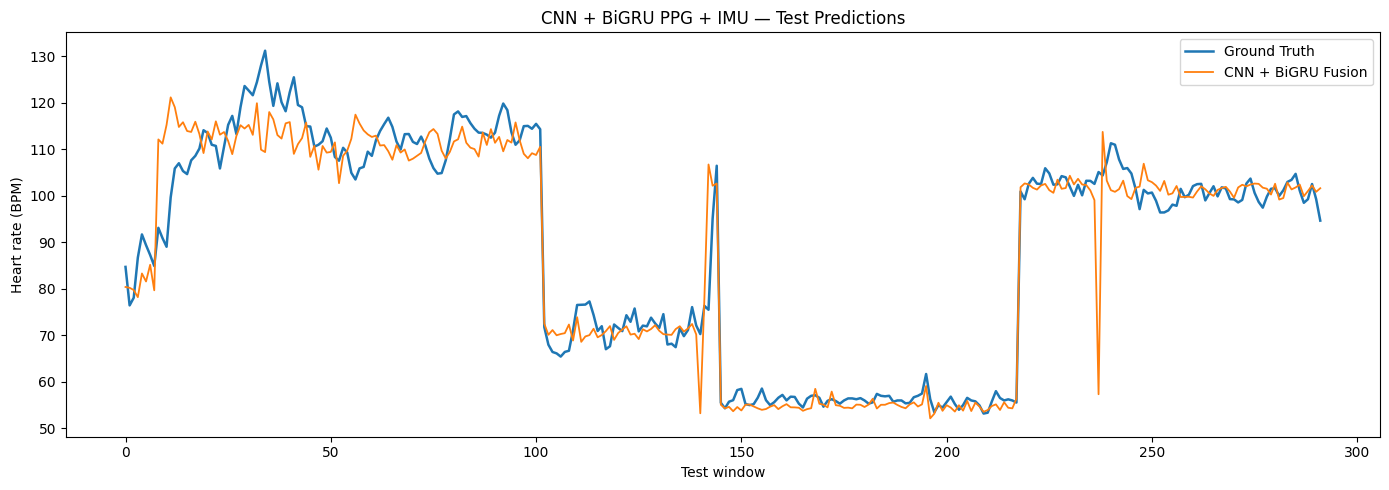

In [18]:
plt.figure(figsize=(14, 5))
plt.plot(y_test, label="Ground Truth", linewidth=1.8)
plt.plot(y_pred_cnn_bigru, label="CNN + BiGRU Fusion", linewidth=1.3)
plt.xlabel("Test window")
plt.ylabel("Heart rate (BPM)")
plt.title("CNN + BiGRU PPG + IMU — Test Predictions")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Predicted vs true HR

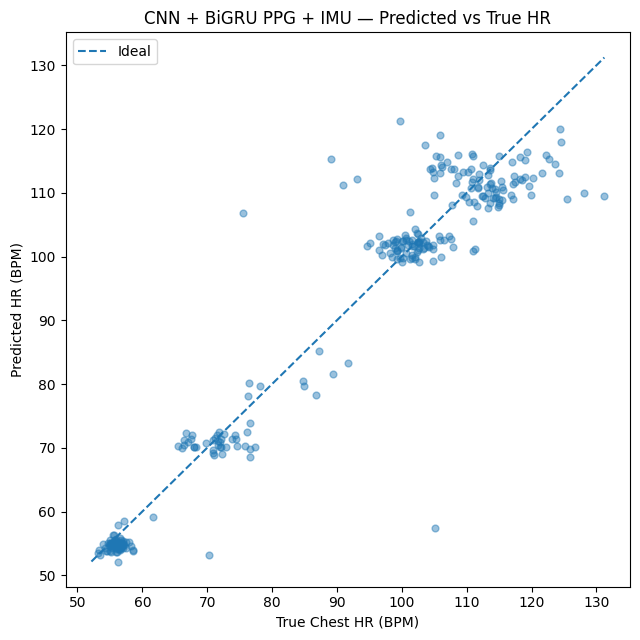

In [19]:
low = float(min(y_test.min(), y_pred_cnn_bigru.min()))
high = float(max(y_test.max(), y_pred_cnn_bigru.max()))

plt.figure(figsize=(6.5, 6.5))
plt.scatter(y_test, y_pred_cnn_bigru, s=24, alpha=0.45)
plt.plot([low, high], [low, high], linestyle="--", linewidth=1.5, label="Ideal")
plt.xlabel("True Chest HR (BPM)")
plt.ylabel("Predicted HR (BPM)")
plt.title("CNN + BiGRU PPG + IMU — Predicted vs True HR")
plt.legend()
plt.tight_layout()
plt.show()

## 20. Per-activity MAE

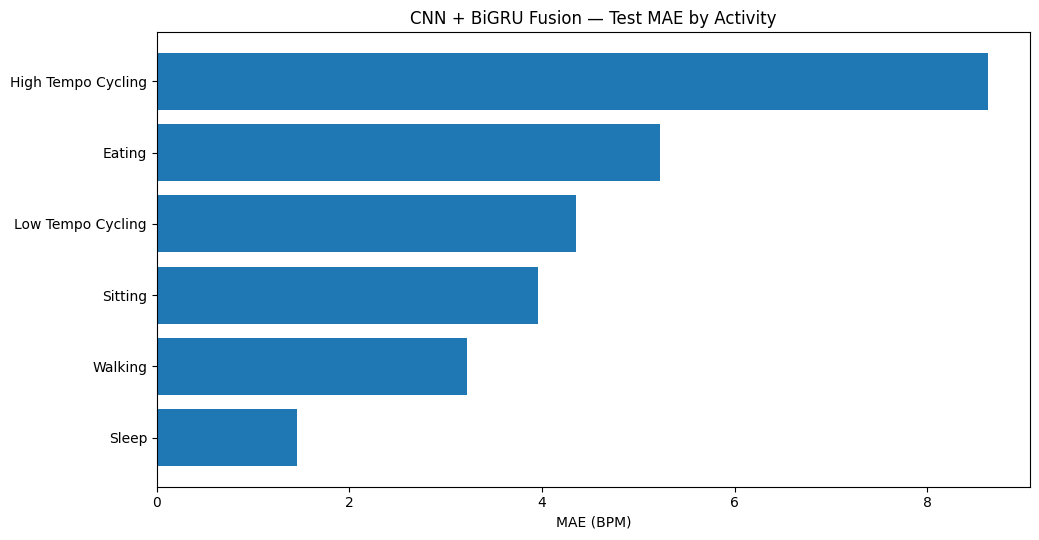

In [20]:
plot_df = cnn_bigru_activity_results.sort_values("MAE_BPM")

plt.figure(figsize=(10.5, 5.5))
plt.barh(
    plot_df["Activity"].str.replace("_", " "),
    plot_df["MAE_BPM"]
)
plt.xlabel("MAE (BPM)")
plt.title("CNN + BiGRU Fusion — Test MAE by Activity")
plt.tight_layout()
plt.show()

## 21. Per-activity correlation

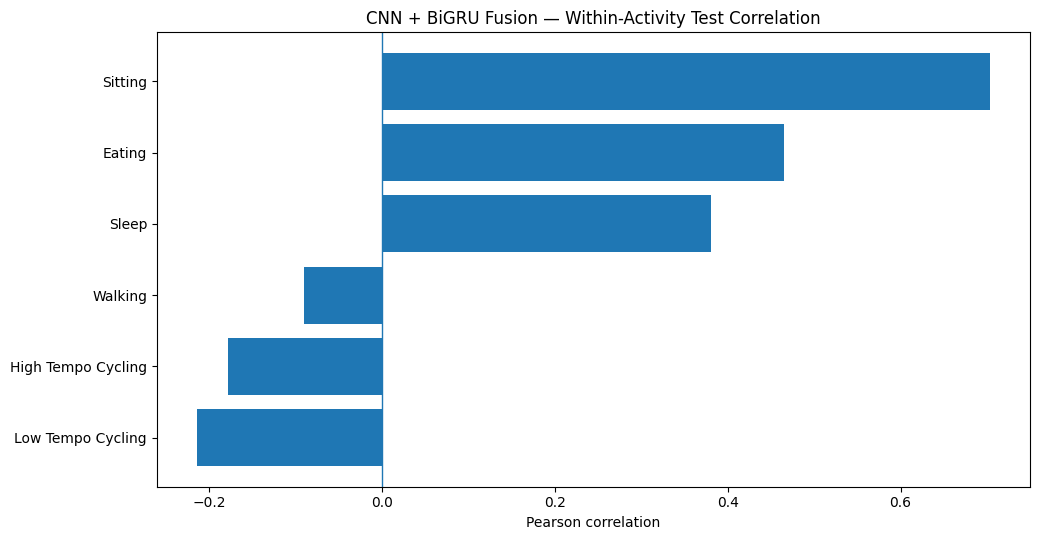

In [21]:
plot_df = cnn_bigru_activity_results.sort_values("Correlation")

plt.figure(figsize=(10.5, 5.5))
plt.barh(
    plot_df["Activity"].str.replace("_", " "),
    plot_df["Correlation"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Pearson correlation")
plt.title("CNN + BiGRU Fusion — Within-Activity Test Correlation")
plt.tight_layout()
plt.show()

## 22. Activity-mean baseline vs CNN + BiGRU

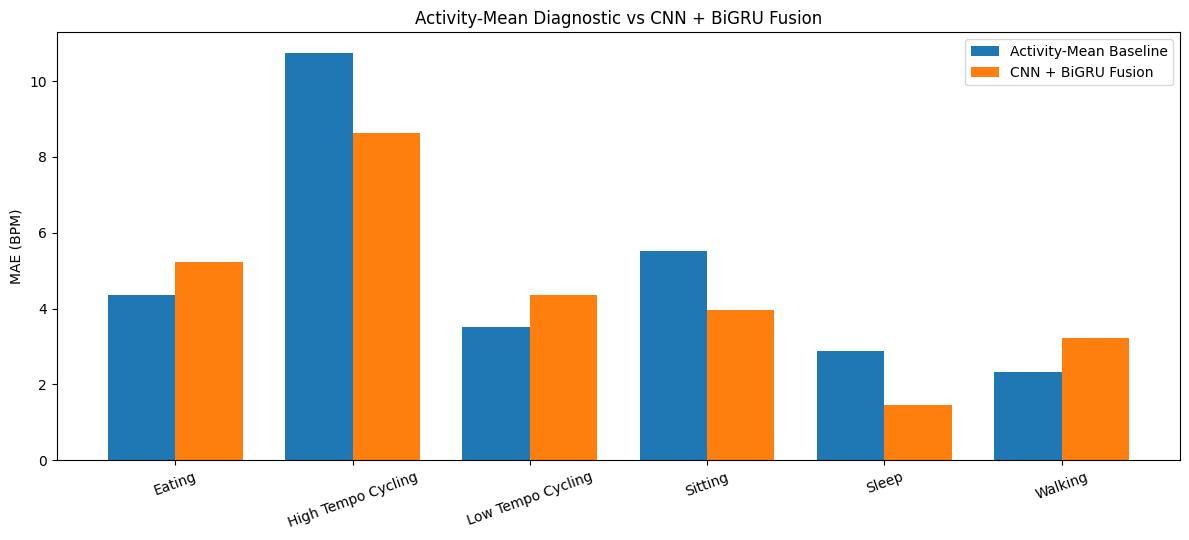

In [22]:
x = np.arange(len(comparison))
width = 0.38

plt.figure(figsize=(12, 5.5))
plt.bar(
    x - width / 2,
    comparison["Activity_Mean_MAE"],
    width,
    label="Activity-Mean Baseline"
)
plt.bar(
    x + width / 2,
    comparison["CNN_BiGRU_MAE"],
    width,
    label="CNN + BiGRU Fusion"
)

plt.xticks(
    x,
    comparison["Activity"].str.replace("_", " "),
    rotation=20
)
plt.ylabel("MAE (BPM)")
plt.title("Activity-Mean Diagnostic vs CNN + BiGRU Fusion")
plt.legend()
plt.tight_layout()
plt.show()

## 23. Conclusion

The CNN + BiGRU fusion model achieved the best overall HR-regression
performance among the evaluated Deep Learning architectures and was
selected as the final HR estimation model.

The model achieved a test MAE of 3.8647 BPM, RMSE of 6.2433 BPM,
R² of 0.9304, and Pearson correlation of 0.9659.

Activity-specific results remain important for assessing performance
under different motion conditions.